# 02 — Phân tích CNN và ablation A3 (RQ2)

Notebook này đọc kết quả **ablation A3** để trả lời RQ2: khi tăng số ván huấn
luyện từ 250 đến tối đa ván thực có, độ chính xác của CNN thay đổi thế nào
theo từng tình huống **thắng ngay**, **chặn** và **kiểm soát trung tâm**?

- Cấu hình: `configs/ablation_a3_cnn_data.yaml`
- Script sinh kết quả: `scripts/run_ablation_a3.py`
- Bảng tổng hợp: `results/tables/ablation_a3_results.csv`
- Log thô: `results/logs/ablation_a3_<run_id>.csv`,
  `results/logs/train_cnn_<run_id>.csv`,
  `checkpoints/level5_cnn/test_evaluation_<run_id>.json`

Chạy lại toàn bộ thực nghiệm (từ `Connect_Four/`):

```bash
PYTHONPATH=src python scripts/run_ablation_a3.py \
    --config configs/ablation_a3_cnn_data.yaml
```

Notebook không huấn luyện lại; nó chỉ đọc log đã sinh để bảo đảm mọi con số
truy vết được về một `run_id`.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import pandas as pd
import yaml
from IPython.display import Markdown, display

ROOT = Path.cwd().resolve()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / "configs" / "ablation_a3_cnn_data.yaml").is_file():
        ROOT = candidate
        break
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

CONFIG_PATH = ROOT / "configs" / "ablation_a3_cnn_data.yaml"
TABLE_PATH = ROOT / "results" / "tables" / "ablation_a3_results.csv"
FIGURE_PATH = ROOT / "results" / "figures" / "ablation_a3_accuracy.png"

config = yaml.safe_load(CONFIG_PATH.read_text(encoding="utf-8"))
table = pd.read_csv(TABLE_PATH)
assert not table.empty, "Chưa có bảng A3; hãy chạy scripts/run_ablation_a3.py trước."

print("Config:", config["name"])
print("Cohort:", config["cohort"], "| sizes:", config["dataset_sizes_games"])
print("Số dòng kết quả:", len(table))
print("Ablation run:", table["ablation_run_id"].iloc[0])

Config: ablation_a3_cnn_data
Cohort: a3 | sizes: [250, 500, 1000, 1332]
Số dòng kết quả: 4
Ablation run: ablation-a3-20261111T150514Z-s20261105


## 1. Thiết kế ablation

Cohort A3 có 2.000 ván nhưng sau khi chia theo ván 70/15/15 và loại trạng thái
trùng/đối xứng, chỉ còn **1.332 ván train**, **254 ván validation** và **264
ván test** có mẫu duy nhất. Validation và test được giữ cố định cho cả bốn mức;
vì vậy mức lớn nhất dùng đúng 1.332 ván train thực có, không phải 2.000 ván của
toàn cohort.

Mỗi mức huấn luyện lại CNN từ đầu với cùng kiến trúc, optimizer, 20 epoch,
batch 64, learning rate 0,001 và seed 20261105. Checkpoint được chọn theo
validation loss thấp nhất; test chỉ đọc một lần cho mỗi lần huấn luyện.

In [2]:
summary_columns = [
    "games",
    "train_games",
    "train_examples",
    "val_examples",
    "test_examples",
    "best_epoch",
    "best_val_loss",
    "test_loss",
    "top1_accuracy",
    "legal_action_rate",
]
summary = table[summary_columns].copy()
summary.columns = [
    "Ván train",
    "Ván train thực",
    "Mẫu train",
    "Mẫu val",
    "Mẫu test",
    "Epoch tốt nhất",
    "Val loss tốt nhất",
    "Test loss",
    "Top-1 tổng thể",
    "Tỷ lệ dự đoán hợp lệ",
]
display(summary.style.format({
    "Val loss tốt nhất": "{:.4f}",
    "Test loss": "{:.4f}",
    "Top-1 tổng thể": "{:.2%}",
    "Tỷ lệ dự đoán hợp lệ": "{:.2%}",
}))

,Ván train,Ván train thực,Mẫu train,Mẫu val,Mẫu test,Epoch tốt nhất,Val loss tốt nhất,Test loss,Top-1 tổng thể,Tỷ lệ dự đoán hợp lệ
0,250,250,10857,5070,5012.000000,3,1.3832,1.3959,47.19%,100.00%
1,500,500,21098,5070,5012.000000,7,1.2830,1.3088,51.74%,100.00%
2,1000,1000,40561,5070,5012.000000,5,1.1637,1.1589,55.35%,100.00%
3,1332,1332,53284,5070,5012.000000,5,1.1150,1.1106,57.08%,100.00%


## 2. Đường cong học theo số ván

Hai hình dưới cho thấy loss/accuracy trên train và validation của từng mức dữ
liệu. Đường validation là căn cứ chọn checkpoint; đường train chỉ dùng để nhận
diện overfitting.

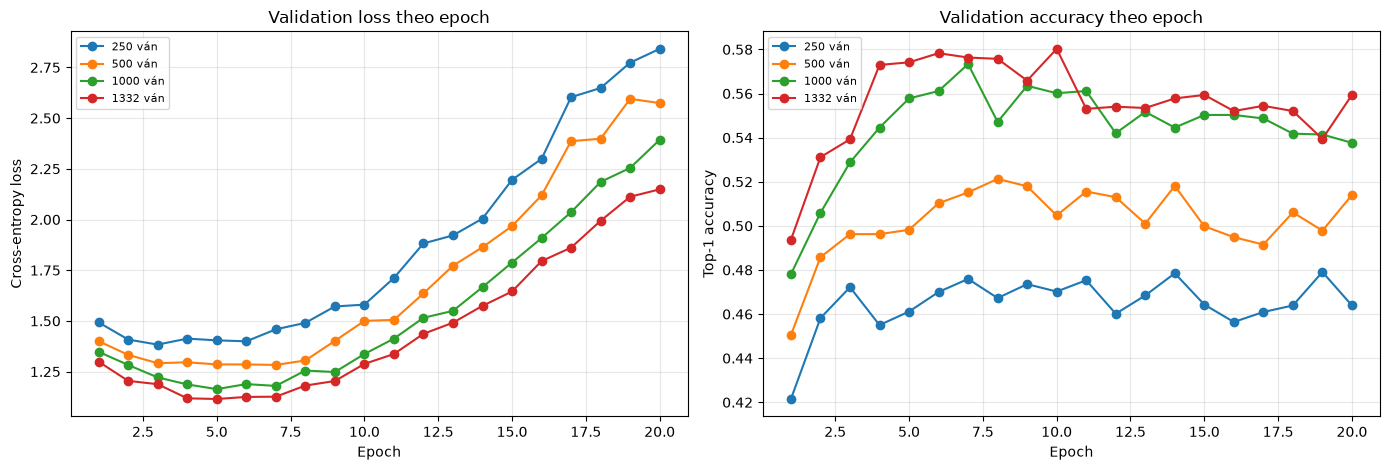

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for _, row in table.iterrows():
    log = pd.read_csv(ROOT / row["training_log"])
    label = f"{int(row['games'])} ván"
    axes[0].plot(log["epoch"], log["val_loss"], marker="o", label=label)
    axes[1].plot(log["epoch"], log["val_accuracy"], marker="o", label=label)
axes[0].set_title("Validation loss theo epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[1].set_title("Validation accuracy theo epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Top-1 accuracy")
for axis in axes:
    axis.grid(alpha=0.3)
    axis.legend(fontsize=8)
fig.tight_layout()
fig.savefig(ROOT / "results" / "figures" / "ablation_a3_learning_curves.png", dpi=160)
plt.show()

## 3. Độ chính xác theo tình huống (RQ2)

Cách phân loại trong `evaluation/situations.py`:

| Tình huống | Điều kiện | Cách tính accuracy chính |
| --- | --- | --- |
| `win_now` | Người đang đi có ít nhất một nước thắng ngay | Dự đoán có nằm trong tập nước thắng ngay (tactical accuracy) |
| `block` | Không thắng ngay, nhưng đối thủ có ít nhất một nước thắng ngay | Dự đoán có chặn được một nước thắng của đối thủ (tactical accuracy) |
| `center_control` | Không có nước thắng/chặn ngay và cột giữa còn trống | Top-1 khớp nhãn Alpha-Beta trong nhóm vị trí này |

Cột `center_control_situation_accuracy` (tỷ lệ chọn đúng cột giữa) được giữ
như **chẩn đoán**, không dùng làm accuracy chính: Alpha-Beta depth 4 chỉ chọn
cột giữa ở khoảng 22,8% vị trí không có nước chiến thuật, nên một mô hình học
tốt nhãn Alpha-Beta không nhất thiết luôn chọn cột giữa.

,Ván train,Top-1 tổng thể,Thắng ngay (tactical),Chặn (tactical),Trung tâm (top-1),Trung tâm (tỷ lệ chọn cột 3)
0,250,47.19%,42.37%,52.99%,41.55%,38.51%
1,500,51.74%,60.44%,71.30%,46.44%,28.83%
2,1000,55.35%,58.57%,73.59%,50.87%,21.62%
3,1332,57.08%,59.81%,77.64%,52.65%,27.57%


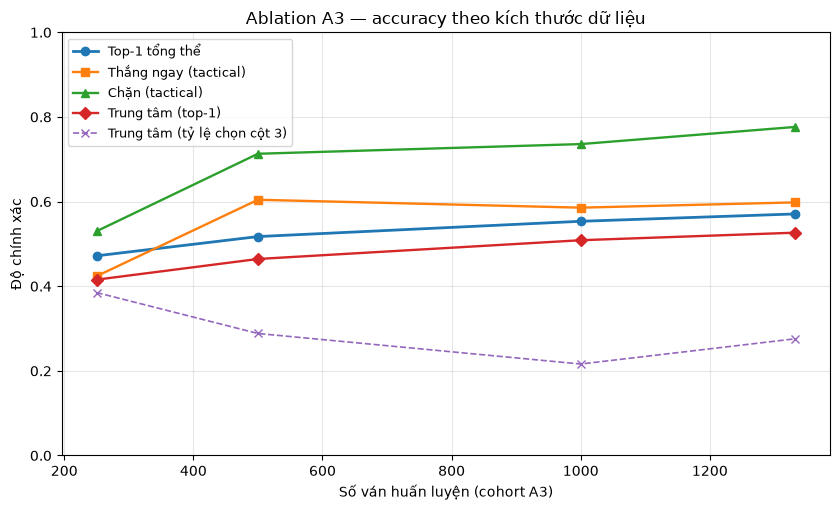

In [4]:
rq2 = table[[
    "games",
    "top1_accuracy",
    "win_now_situation_accuracy",
    "block_situation_accuracy",
    "center_control_top1_accuracy",
    "center_control_situation_accuracy",
]].copy()
rq2.columns = [
    "Ván train",
    "Top-1 tổng thể",
    "Thắng ngay (tactical)",
    "Chặn (tactical)",
    "Trung tâm (top-1)",
    "Trung tâm (tỷ lệ chọn cột 3)",
]
display(rq2.style.format({
    "Top-1 tổng thể": "{:.2%}",
    "Thắng ngay (tactical)": "{:.2%}",
    "Chặn (tactical)": "{:.2%}",
    "Trung tâm (top-1)": "{:.2%}",
    "Trung tâm (tỷ lệ chọn cột 3)": "{:.2%}",
}))

fig, axis = plt.subplots(figsize=(8.5, 5.2))
axis.plot(table["games"], table["top1_accuracy"], marker="o", linewidth=2,
          label="Top-1 tổng thể")
axis.plot(table["games"], table["win_now_situation_accuracy"], marker="s",
          linewidth=1.7, label="Thắng ngay (tactical)")
axis.plot(table["games"], table["block_situation_accuracy"], marker="^",
          linewidth=1.7, label="Chặn (tactical)")
axis.plot(table["games"], table["center_control_top1_accuracy"], marker="D",
          linewidth=1.7, label="Trung tâm (top-1)")
axis.plot(table["games"], table["center_control_situation_accuracy"], marker="x",
          linewidth=1.2, linestyle="--", label="Trung tâm (tỷ lệ chọn cột 3)")
axis.set_xlabel("Số ván huấn luyện (cohort A3)")
axis.set_ylabel("Độ chính xác")
axis.set_ylim(0, 1)
axis.grid(alpha=0.3)
axis.legend(fontsize=9)
axis.set_title("Ablation A3 — accuracy theo kích thước dữ liệu")
fig.tight_layout()
fig.savefig(FIGURE_PATH, dpi=160)
plt.show()

## 4. Số vị trí trong từng tình huống

Vì validation/test cố định, số vị trí mỗi tình huống không đổi giữa các mức;
đây là mẫu số của từng accuracy ở trên.

In [5]:
counts = table[["games", "win_now_n", "block_n", "center_control_n", "other_n"]].copy()
counts.columns = ["Ván train", "Thắng ngay", "Chặn", "Trung tâm", "Khác"]
counts["Tổng"] = counts[["Thắng ngay", "Chặn", "Trung tâm", "Khác"]].sum(axis=1)
display(counts.style.format("{:.0f}"))

,Ván train,Thắng ngay,Chặn,Trung tâm,Khác,Tổng
0,250,321,568,3090,1033,5012
1,500,321,568,3090,1033,5012
2,1000,321,568,3090,1033,5012
3,1332,321,568,3090,1033,5012


## 5. Trả lời RQ2

Đoạn dưới tự sinh kết luận từ bảng, không ghi tay số liệu. Diễn giải cần đọc
kèm giới hạn ở mục 6.

In [6]:
first = table.iloc[0]
last = table.iloc[-1]
delta_top1 = last["top1_accuracy"] - first["top1_accuracy"]
delta_win = last["win_now_situation_accuracy"] - first["win_now_situation_accuracy"]
delta_block = last["block_situation_accuracy"] - first["block_situation_accuracy"]
delta_center = last["center_control_top1_accuracy"] - first["center_control_top1_accuracy"]

display(Markdown(f'''
**Kết quả đo được (một seed, một bộ chia dữ liệu):**

- Top-1 tổng thể tăng từ **{first['top1_accuracy']:.2%}** (250 ván) lên
  **{last['top1_accuracy']:.2%}** ({int(last['games'])} ván), tức
  **{delta_top1:+.2%}**.
- Thắng ngay (tactical) thay đổi **{delta_win:+.2%}**, từ
  {first['win_now_situation_accuracy']:.2%} lên
  {last['win_now_situation_accuracy']:.2%}.
- Chặn (tactical) thay đổi **{delta_block:+.2%}**, từ
  {first['block_situation_accuracy']:.2%} lên
  {last['block_situation_accuracy']:.2%}.
- Trung tâm (top-1) thay đổi **{delta_center:+.2%}**, từ
  {first['center_control_top1_accuracy']:.2%} lên
  {last['center_control_top1_accuracy']:.2%}.

Nhìn chung, tăng dữ liệu cải thiện độ chính xác tổng thể và cả ba tình huống.
Mức tăng lớn nhất thường thuộc về **chặn** và **thắng ngay**; **kiểm soát trung
tâm** là tình huống khó nhất trong ba nhóm và vẫn thấp hơn top-1 tổng thể.
'''))


**Kết quả đo được (một seed, một bộ chia dữ liệu):**

- Top-1 tổng thể tăng từ **47.19%** (250 ván) lên
  **57.08%** (1332 ván), tức
  **+9.90%**.
- Thắng ngay (tactical) thay đổi **+17.45%**, từ
  42.37% lên
  59.81%.
- Chặn (tactical) thay đổi **+24.65%**, từ
  52.99% lên
  77.64%.
- Trung tâm (top-1) thay đổi **+11.10%**, từ
  41.55% lên
  52.65%.

Nhìn chung, tăng dữ liệu cải thiện độ chính xác tổng thể và cả ba tình huống.
Mức tăng lớn nhất thường thuộc về **chặn** và **thắng ngay**; **kiểm soát trung
tâm** là tình huống khó nhất trong ba nhóm và vẫn thấp hơn top-1 tổng thể.


## 6. Kiểm tra chất lượng nhãn Alpha-Beta (tùy chọn)

Nhãn được sinh bởi Alpha-Beta depth 4, không phải nước tối ưu toán học. Trong
một số vị trí có nước thắng ngay, Alpha-Beta depth 4 vẫn có thể chọn nước khác;
khi đó tactical accuracy mới là thước đo đúng cho tình huống thắng ngay, còn
top-1 phản ánh mức khớp nhãn (kể cả lỗi của nhãn).

Cell dưới chỉ chạy khi còn dữ liệu sinh trong `data/generated/splits/`.

In [7]:
data_dir = ROOT / config["data_dir"]
if (data_dir / "test.jsonl").is_file():
    from connect_four.evaluation.situations import classify_position
    from connect_four.training.train_supervised import _load_split

    states, labels = _load_split(data_dir, "test", cohort=config["cohort"])
    win_now = 0
    label_not_winning = 0
    for state, label in zip(states, labels):
        situation = classify_position(state)
        if situation.name == "win_now":
            win_now += 1
            label_not_winning += int(int(label) not in situation.winning_moves)
    display(Markdown(
        f"Có **{win_now}** vị trí thắng ngay trong test; "
        f"**{label_not_winning}** nhãn Alpha-Beta không phải nước thắng ngay "
        f"({label_not_winning / win_now:.1%})."
    ))
else:
    print("Không có data/generated/splits/test.jsonl; bỏ qua kiểm tra nhãn.")

Có **321** vị trí thắng ngay trong test; **98** nhãn Alpha-Beta không phải nước thắng ngay (30.5%).

## 7. Giới hạn

- Chỉ chạy **một seed** (20261105) và một cách chia dữ liệu; chưa có khoảng tin
  cậy hay lặp seed. Không nên suy rộng thành quy luật cho mọi seed.
- Validation/test cố định giúp so sánh công bằng giữa các mức, nhưng mức lớn
  nhất chỉ dùng 1.332 ván train thực có (sau dedupe), không phải toàn bộ 2.000
  ván của cohort A3.
- Nhãn Alpha-Beta depth 4 có thể chưa tối ưu; vì vậy báo cáo tách top-1 (khớp
  nhãn) và tactical accuracy (đúng yêu cầu chiến thuật).
- `center_control` là nhóm vị trí không có nước thắng/chặn ngay và cột giữa còn
  trống. Tỷ lệ chọn cột giữa chỉ là chẩn đoán, không phải mục tiêu duy nhất của
  chiến lược kiểm soát trung tâm.
- Issue #22 không đo win rate đối kháng trước Alpha-Beta; hạng mục đó thuộc
  đánh giá giải đấu/ablation khác.